# 01 · Preprocessing — Chen 2020 NPC (malignant compartment)

Nasopharyngeal carcinoma (EBV-associated), 10x, 14 samples. Isolate malignant cells,
derive a per-sample cell threshold, select overdispersed genes, PCA (n_pcs off the
scree), Harmony on `sample`, embed, and evaluate **Gate 1**.

**Gate 1 (01→02).** After Harmony + DR, is the malignant structure both **mixed**
(sample-integrated) and **continuous** (one connected gradient)? NO-GO if it clusters
by sample or breaks into islands — *do not force a trajectory* (importance HIGH). Judged
on the **regenerated embedding across an integration-strength sweep** with a
per-neighborhood mixing metric — never a scalar alone (Kürten G1 lesson). Sub-region
biology (cell cycle, meta-programs) is settled **before** the GO decision.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
import warnings, logging; warnings.filterwarnings('ignore')
logging.disable(logging.INFO)   # silence harmonypy per-iteration INFO logs
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())          # Chen2020_Head-and-Neck
cat  = os.path.basename(os.path.dirname(os.getcwd()))  # Head-and-Neck
pth  = os.path.join(*([os.pardir]*6))          # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
pth_raw  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA', 'scripts'))
from load import load_CCCA_adata

### Load & isolate the malignant compartment

The loader auto-detects UMI counts (→ `normalize_total` + `log1p`) and sets `celltype`.

In [ ]:
adata = load_CCCA_adata(pth_raw, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print(adata.obs.celltype.value_counts().to_string())
mal = adata[adata.obs.celltype == 'Malignant'].copy()
print('\nmalignant:', mal.shape, '| samples:', mal.obs['sample'].nunique())

full atlas: (71896, 36695)
celltype
B_cell            19076
T_cell            19066
NK_cell            6969
Macrophage         5062
Malignant          3763
Plasma             3415
Epithelial         2575
Endothelial        1944
Dendritic           856
Lymphovascular      662
Fibroblast          434
Myofibroblast       353
Mast                169

malignant: (3763, 36695) | samples: 14


### Sample threshold — derived, not inherited (C1)

Puram's ≥100 constant is not portable. Sort per-sample malignant counts and cut at the
**spillover gap** (the largest multiplicative jump). **C3 caveat — this dataset violates
the clean-gap assumption:** the largest global gap is at the *top* of the distribution
(driven by two dominant patients, P11 & P01), and a naive `argmax(ratios)` would keep only
2 samples — too few to integrate or to assess mixing. The true spillover separatrix (real
tumor vs ambient/doublet spillover) sits in the lower half, so restrict the gap search to
gaps whose upper count is ≤ the per-sample median. Both derivations are shown below.

In [ ]:
n = mal.obs['sample'].value_counts()          # sorted desc
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
med = np.median(vals)
naive = int(np.argmax(ratios))
cand  = [i for i in range(len(ratios)) if vals[i] <= med]
best  = max(cand, key=lambda i: ratios[i])
thr   = int(np.sqrt(vals[best]*vals[best+1]))   # geometric-mean threshold
keep  = n.index[n >= thr]
print('per-sample malignant counts:'); print(n.to_string())
print(f'\nNAIVE global-argmax gap {int(vals[naive])}->{int(vals[naive+1])} '
      f'(x{ratios[naive]:.2f}) would keep only {naive+1} samples  [rejected: heavy head]')
print(f'median per-sample count = {med:.0f}')
print(f'DERIVED spillover gap {int(vals[best])}->{int(vals[best+1])} (x{ratios[best]:.2f}) '
      f'-> threshold = geomean = {thr}')
print(f'keep n>={thr}: {sorted(keep.tolist())} = {len(keep)} samples, '
      f'{int(mal.obs["sample"].isin(keep).sum())} cells')

per-sample malignant counts:
sample
P11    1814
P01     838
P12     236
P06     234
P14     197
P05     136
P04     112
P03     107
P02      36
P08      25
P07      13
P10       6
P15       5
P09       4

NAIVE global-argmax gap 838->236 (x3.55) would keep only 2 samples  [rejected: heavy head]
median per-sample count = 110
DERIVED spillover gap 107->36 (x2.97) -> threshold = geomean = 62
keep n>=62: ['P01', 'P03', 'P04', 'P05', 'P06', 'P11', 'P12', 'P14'] = 8 samples, 3674 cells


after threshold: (3674, 36695)


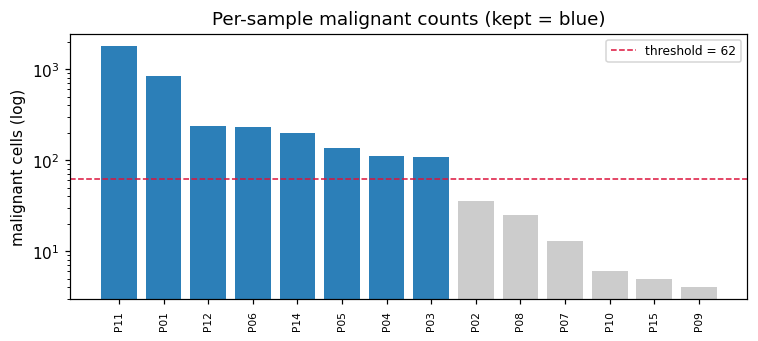

In [ ]:
fig, ax = plt.subplots(figsize=(7,3.2))
colors = ['#2c7fb8' if s in set(keep) else '#cccccc' for s in n.index]
ax.bar(range(len(n)), n.values, color=colors)
ax.axhline(thr, color='crimson', lw=1, ls='--', label=f'threshold = {thr}')
ax.set_yscale('log'); ax.set_xticks(range(len(n))); ax.set_xticklabels(n.index, rotation=90, size=7)
ax.set_ylabel('malignant cells (log)'); ax.set_title('Per-sample malignant counts (kept = blue)')
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
mal = mal[mal.obs['sample'].isin(keep)].copy()
print('after threshold:', mal.shape)

### Gene filter & overdispersed selection (data-driven)

`scf.pp.find_overdispersed` fits a GAM mean–variance trend and keeps genes above it —
no inherited count.

In [ ]:
sc.pp.filter_genes(mal, min_cells=3)
print('after gene filter:', mal.shape)
scf.pp.find_overdispersed(mal)
print('over-dispersed genes:', int(mal.var.highly_variable.sum()))
mal.raw = mal
m = mal[:, mal.var.highly_variable].copy()
sc.pp.scale(m, max_value=10)

after gene filter: (3674, 22080)
Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1290 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 1290


### PCA & scree-derived n_pcs (C1)

Elbow via maximum distance below the (0,1)→(1,0) chord of the normalized
variance-ratio curve — not the inherited 40.

variance_ratio[:12]: [0.0754, 0.064, 0.0317, 0.0218, 0.0174, 0.0129, 0.0116, 0.0099, 0.0093, 0.0088, 0.0077, 0.0075]
scree-derived n_pcs = 6


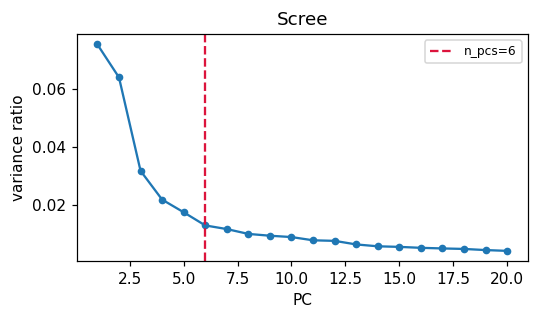

In [ ]:
sc.tl.pca(m, n_comps=50, svd_solver='arpack', random_state=SEED)
vr = m.uns['pca']['variance_ratio']
x = np.arange(1, len(vr)+1)
xn = (x-x.min())/(x.max()-x.min()); yn = (vr-vr.min())/(vr.max()-vr.min())
NPCS = int(np.argmax((1-xn)-yn)) + 1
print('variance_ratio[:12]:', np.round(vr[:12],4).tolist())
print('scree-derived n_pcs =', NPCS)
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(x[:20], vr[:20], 'o-', ms=4); ax.axvline(NPCS, color='crimson', ls='--', label=f'n_pcs={NPCS}')
ax.set_xlabel('PC'); ax.set_ylabel('variance ratio'); ax.set_title('Scree'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

### Gate 1 — integration-strength sweep with a per-neighborhood mixing metric

Never judge mixing on a scalar. Sweep Harmony `theta`, and for each measure the mean
**fraction of a cell's 30 nearest neighbors drawn from a *different* sample** (higher =
better mixed). Under perfect mixing this equals 1−Σpₛ². Also count **patient-pure Leiden
clusters** (dominant patient >60% of the cluster and >1.5× that patient's global share).

In [ ]:
samp = m.obs['sample']; p = samp.value_counts(normalize=True)
ceiling = 1 - float((p.values**2).sum())
print(f'sample shares: {p.round(3).to_dict()}')
print(f'two largest samples = {p.nlargest(2).sum():.2f} of cells (P11+P01)')
print(f'diff-sample neighbor fraction ceiling (perfect mixing) = {ceiling:.3f}\n')
def mixing(rep, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    sv = samp.values
    return float((sv[idx] != sv[:,None]).mean())
pre = mixing(m.obsm['X_pca'][:,:NPCS])
print(f'PRE-Harmony diff-sample neighbor frac = {pre:.3f}')
sweep = {}
for theta in [1,2,3]:
    mm = m.copy()
    sce.pp.harmony_integrate(mm,'sample',theta=theta,max_iter_harmony=20,random_state=SEED,verbose=False)
    sc.pp.neighbors(mm,n_neighbors=15,n_pcs=NPCS,use_rep='X_pca_harmony',random_state=SEED)
    sc.tl.leiden(mm,resolution=0.5,random_state=SEED,flavor='igraph',n_iterations=2,directed=False)
    ct=pd.crosstab(mm.obs['leiden'],mm.obs['sample']); fr=ct.div(ct.sum(1),axis=0)
    dom=fr.max(1); ds=fr.idxmax(1); exc=np.array([dom[c]/p[ds[c]] for c in ct.index])
    pure=(dom>0.60)&(exc>1.5); pf=ct.sum(1)[pure.values].sum()/mm.n_obs
    mx=mixing(mm.obsm['X_pca_harmony'][:,:NPCS])
    sweep[theta]=(mx,int(pure.sum()),ct.shape[0],pf)
    print(f'theta={theta}: diff-sample nbr={mx:.3f} | patient-pure clusters={int(pure.sum())}/{ct.shape[0]} '
          f'({pf:.0%} of cells)')

sample shares: {'P11': 0.494, 'P01': 0.228, 'P12': 0.064, 'P06': 0.064, 'P14': 0.054, 'P05': 0.037, 'P04': 0.03, 'P03': 0.029}
two largest samples = 0.72 of cells (P11+P01)
diff-sample neighbor fraction ceiling (perfect mixing) = 0.690

PRE-Harmony diff-sample neighbor frac = 0.047
theta=1: diff-sample nbr=0.127 | patient-pure clusters=8/11 (73% of cells)
theta=2: diff-sample nbr=0.297 | patient-pure clusters=5/10 (56% of cells)
theta=3: diff-sample nbr=0.502 | patient-pure clusters=1/9 (1% of cells)


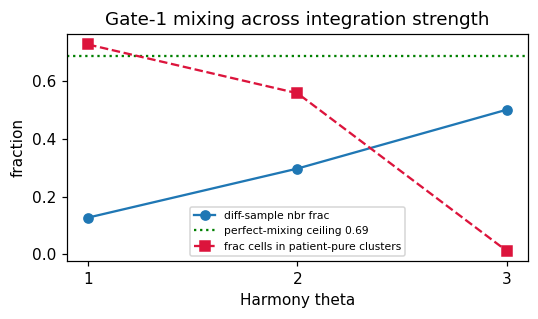

In [ ]:
fig, ax = plt.subplots(figsize=(5,3))
th=list(sweep); ax.plot(th,[sweep[t][0] for t in th],'o-',label='diff-sample nbr frac')
ax.axhline(ceiling,color='green',ls=':',label=f'perfect-mixing ceiling {ceiling:.2f}')
ax.plot(th,[sweep[t][3] for t in th],'s--',color='crimson',label='frac cells in patient-pure clusters')
ax.set_xlabel('Harmony theta'); ax.set_ylabel('fraction'); ax.set_xticks(th)
ax.set_title('Gate-1 mixing across integration strength'); ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

**Sweep read.** At biologically-reasonable integration (theta 1–2), a majority of cells
sit in patient-pure clusters (73% → 56%) and mixing stays far below ceiling. Only extreme
theta=3 collapses the patient signal — but that over-integrates (a detached speck appears;
mixing still under ceiling), forcing patient-private CNV states on top of one another. We
proceed at **theta=2** (the balance: continuous, integrated as far as possible without
over-correction) and judge Gate 1 on that embedding.

In [ ]:
sce.pp.harmony_integrate(m,'sample',theta=2,max_iter_harmony=20,random_state=SEED,verbose=False)
sc.pp.neighbors(m,n_neighbors=15,n_pcs=NPCS,use_rep='X_pca_harmony',random_state=SEED)
sc.tl.umap(m,random_state=SEED,spread=1.0,min_dist=0.5)
sc.tl.leiden(m,resolution=0.5,random_state=SEED,flavor='igraph',n_iterations=2,directed=False)
print('theta=2 embedding:', m.n_obs, 'cells,', m.obs.leiden.nunique(),'clusters')

theta=2 embedding: 3674 cells, 10 clusters


### Continuity — connected components on a UMAP radius graph

Radius = 6× the median nearest-neighbor distance; keep the largest component.

In [ ]:
X=m.obsm['X_umap']; nn=NearestNeighbors(n_neighbors=2).fit(X); d,_=nn.kneighbors(X)
r=6*np.median(d[:,1]); A=NearestNeighbors(radius=r).fit(X).radius_neighbors_graph(X)
ncomp,labcc=connected_components(csr_matrix(A),directed=False)
sizes=pd.Series(labcc).value_counts()
print(f'connected components: {ncomp}; largest = {sizes.iloc[0]}/{m.n_obs} = {sizes.iloc[0]/m.n_obs:.3f}')
print('-> continuous (single component)' if ncomp==1 else '-> fragmented')

connected components: 1; largest = 3674/3674 = 1.000
-> continuous (single component)


### Biology before geometry — settle sub-region identity

Annotate each Leiden cluster by its dominant 3CA meta-program (`mp_top`, from the published
atlas) and cycling fraction, and cross-tabulate against `sample`. This decides whether the
sub-regions are a shared developmental axis or patient/proliferation structure — *before*
the GO.

In [ ]:
lab={}
for cl in m.obs['leiden'].cat.categories:
    sub=m.obs[m.obs.leiden==cl]; mp=sub['mp_top'].mode().iloc[0]
    cyc=(sub['cell_cycle_phase']!='Not cycling').mean()
    lab[cl]=f'{mp}'+(' (cyc)' if cyc>0.5 else '')
m.obs['state']=m.obs['leiden'].map(lab).astype('category')
ct=pd.crosstab(m.obs['leiden'],m.obs['sample']); fr=ct.div(ct.sum(1),axis=0)
tab=pd.DataFrame({'n':ct.sum(1),'state':[lab[c] for c in ct.index],
                  'dom_sample':fr.idxmax(1).values,'dom_frac':fr.max(1).round(2).values,
                  'cyc':[round((m.obs.loc[m.obs.leiden==c,'cell_cycle_phase']!='Not cycling').mean(),2) for c in ct.index]})
print(tab.to_string())
print('\npatient-pure non-cycling clusters (e.g. cl8/cl9 = 99% P11) are NOT explained by '
      'cell cycle -> genuine patient-private states, not a shared axis')

          n                    state dom_sample  dom_frac   cyc
leiden                                                         
0       629  Cell Cycle - G1/S (cyc)        P01      0.75  0.56
1       520    Interferon/MHC-II (I)        P11      0.32  0.14
2       158  Cell Cycle - G2/M (cyc)        P01      0.66  0.89
3       120                   EpiSen        P03      0.60  0.02
4       345  Cell Cycle - G2/M (cyc)        P11      0.36  0.95
5       171                   Stress        P12      0.56  0.21
6       352        Cell Cycle - G2/M        P11      0.93  0.46
7       464       Protein maturation        P11      0.49  0.13
8       648                   EMT IV        P11      0.99  0.04
9       267   Translation initiation        P11      0.99  0.18

patient-pure non-cycling clusters (e.g. cl8/cl9 = 99% P11) are NOT explained by cell cycle -> genuine patient-private states, not a shared axis


### Gate 1 diagnostic — the embedding itself

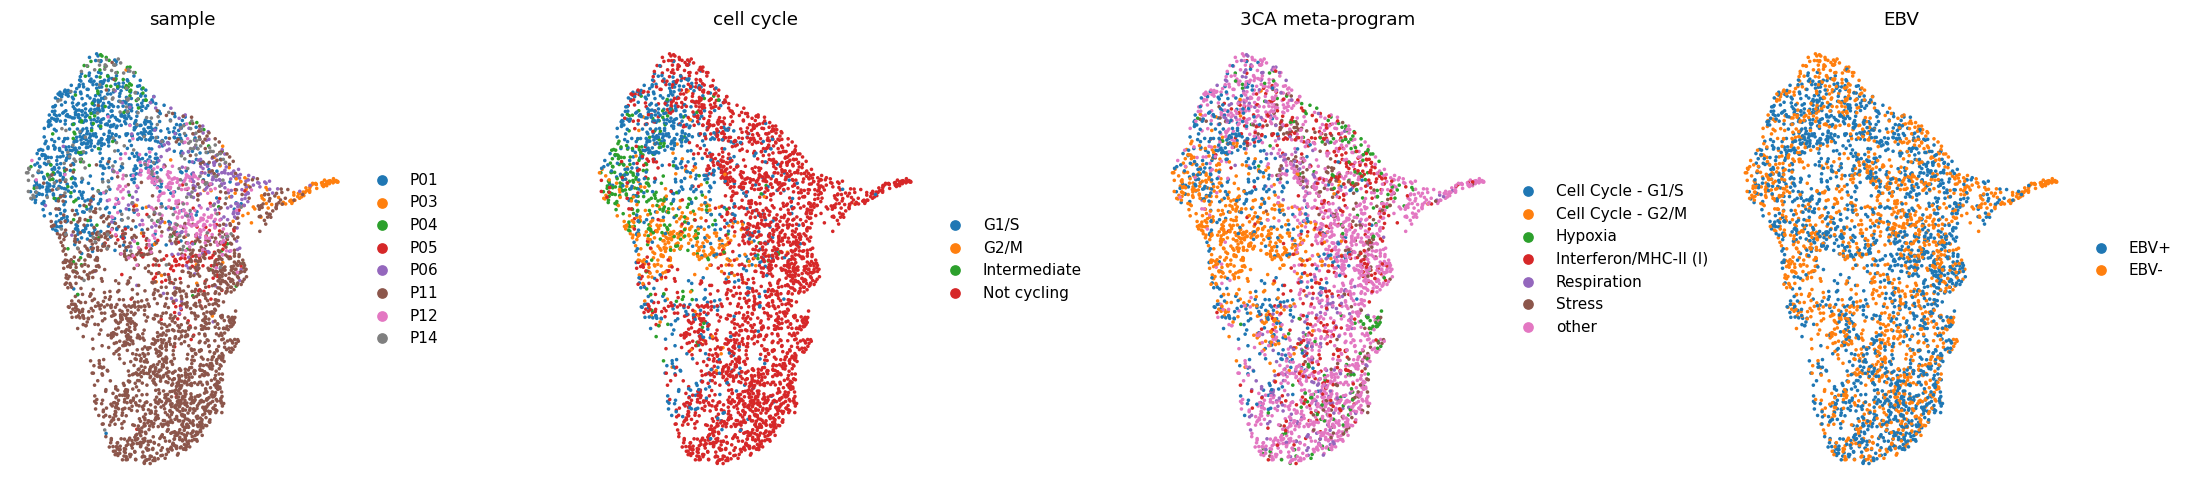

In [ ]:
top=m.obs['mp_top'].value_counts().index[:6].tolist()
m.obs['_mp6']=pd.Categorical([x if x in top else 'other' for x in m.obs['mp_top'].astype(str)])
fig,axes=plt.subplots(1,4,figsize=(20,4.6))
for ax,(col,ttl) in zip(axes,[('sample','sample'),('cell_cycle_phase','cell cycle'),
                              ('_mp6','3CA meta-program'),('ebv','EBV')]):
    sc.pl.umap(m,color=col,ax=ax,show=False,legend_loc='right margin',title=ttl,size=22,frameon=False)
fig.tight_layout(); plt.show()

### GATE 1 = NO-GO

- **Mixed?** **No.** Across the integration sweep the malignant structure clusters by
  **sample**: 56% of cells sit in patient-pure clusters at theta=2 (73% at theta=1), and the
  purest clusters (cl8/cl9, 99% P11) are **non-cycling** — patient-private CNV states, not a
  shared developmental gradient. P11+P01 alone are 72% of the 3,674 malignant cells, so
  Harmony cannot integrate without erasing real per-tumor biology (theta=3 does exactly that
  and over-corrects).
- **Continuous?** Yes (single component) — but Gate 1 requires **both**, and mixing fails.

Per the binding spec, this is a **NO-GO**: *do not force a trajectory.* The Chen 2020
malignant compartment is too small and too patient-dominated to yield a sample-integrated
continuous cell-state manifold. **Stop the gate chain; no manifold/signatures/correlation/
modules notebooks are produced.** The unconditional EMT-TF expression step follows as
notebook **02**.

saved processed.h5ad + samples.pdf


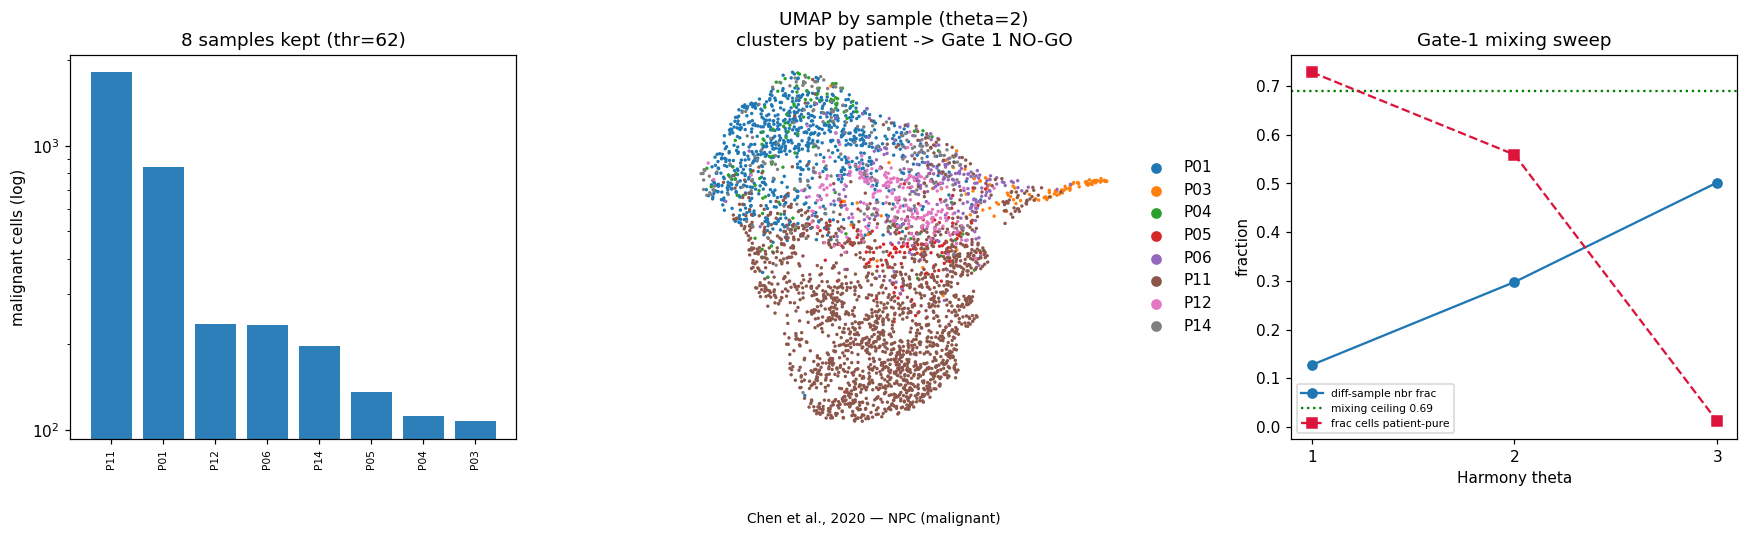

In [ ]:
# persist the processed embedding (used by the expression overlay) + Gate-1 figure
m.obs['n_pcs']=NPCS
m.uns['gate1']={'decision':'NO-GO','theta':2,'n_pcs':NPCS,'ncomp':int(ncomp),
                'frac_patient_pure_cells':round(sweep[2][3],3),
                'diff_sample_nbr':round(sweep[2][0],3),'ceiling':round(ceiling,3)}
m.write(os.path.join(pth_out,'processed.h5ad'))

fig,axes=plt.subplots(1,3,figsize=(16,4.6))
n2=mal.obs['sample'].value_counts()
axes[0].bar(range(len(n2)),n2.values,color=['#2c7fb8']*len(n2))
axes[0].set_yscale('log'); axes[0].set_xticks(range(len(n2))); axes[0].set_xticklabels(n2.index,rotation=90,size=7)
axes[0].set_ylabel('malignant cells (log)'); axes[0].set_title(f'{len(keep)} samples kept (thr={thr})')
sc.pl.umap(m,color='sample',ax=axes[1],show=False,legend_loc='right margin',
           title='UMAP by sample (theta=2)\nclusters by patient -> Gate 1 NO-GO',size=20,frameon=False)
thl=list(sweep)
axes[2].plot(thl,[sweep[t][0] for t in thl],'o-',label='diff-sample nbr frac')
axes[2].axhline(ceiling,color='green',ls=':',label=f'mixing ceiling {ceiling:.2f}')
axes[2].plot(thl,[sweep[t][3] for t in thl],'s--',color='crimson',label='frac cells patient-pure')
axes[2].set_xlabel('Harmony theta'); axes[2].set_xticks(thl); axes[2].set_ylabel('fraction')
axes[2].set_title('Gate-1 mixing sweep'); axes[2].legend(fontsize=7)
fig.text(.5,-.04,'Chen et al., 2020 — NPC (malignant)',ha='center',size=9)
fig.tight_layout(); fig.savefig(os.path.join(pth_fig,'samples.pdf'),bbox_inches='tight'); plt.show()
print('saved processed.h5ad + samples.pdf')